In [2]:
import sys
import time
import itertools
import pandas as pd
import os
from pathlib import Path
import numpy as np
from typing import Union
import random
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
import matplotlib.font_manager as fm
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, roc_curve, auc, RocCurveDisplay
from sklearn.utils import resample
from sklearn.pipeline import Pipeline
sys.path.insert(1, '..')
from Guidestar_model.DiscretisationFunctions import *
from utilsN.FPKM_functions import *

# ---- Main folder = the repository folder, which holds Data/ (layout described in Data/README.md). ----
# Run this from the folder the file is in, or set the environment variable GUIDESTAR_MAIN_DIR to the repository path.
main_dir = os.environ.get('GUIDESTAR_MAIN_DIR', '..')


In [3]:
seed = 0
np.random.seed(seed)
random.seed(seed)
os.environ["PYTHONHASHSEED"] = str(seed)

In [4]:
GS_gene_list = ['Acly','Hnf4a','Ube2z','Gpam']
blank_no = 7
blank_list = ['Blank' + str(i) for i in range(1,blank_no+1)]
cv_fold = 5
features_to_use = ['meaninten1_frob', 'mindist2_clipped', 'mindist3_clipped', 'size']
blank_ratio = 1
merfish_ratio = None
bft = 0.29
nfovs = 25

GS_filepath = os.path.join(main_dir, 'Data/100uM/output/colocalisation/Cell_LM39_25FOVs_GuidestarGenes_training.csv')
merfish_filepath = os.path.join(main_dir, 'Data/100uM/output/colocalisation/Cell_LM39_25FOVs_MerfishData.csv')
fpkm_path = os.path.join(main_dir, 'Data/100uM/codebook/fpkm_data.tsv')
df_fpkm = pd.read_csv(fpkm_path, sep='\t', header=None, names=['genes','FPKM'])
merfish_data = pd.read_csv(merfish_filepath)
GS_genes_data = pd.read_csv(GS_filepath)
output_dir = 'benchmarking_results/'
if not os.path.exists(output_dir):
    os.mkdir(output_dir)

In [5]:
print('training file used:', GS_filepath)
GS_genes_data = GS_genes_data.loc[GS_genes_data['gene'].isin(GS_gene_list+blank_list)]

type_list = []
for row in range(len(GS_genes_data)):
    if GS_genes_data['Label'].iloc[row] == 0:
        if GS_genes_data['gene'].iloc[row] in blank_list:
            type_list.append('blank')
        elif GS_genes_data['gene'].iloc[row] in GS_gene_list:
            type_list.append('merfishonly')
    elif GS_genes_data['Label'].iloc[row] == 1:
        type_list.append('colocalgene')
        
GS_genes_data['type'] = type_list

# Process features 
temp = GS_genes_data['mindist2'].copy().to_numpy()
temp[~np.isfinite(temp)] = -np.inf
GS_genes_data['mindist2_clipped'] = np.clip(GS_genes_data['mindist2'],a_min=np.min(GS_genes_data['mindist2']),a_max=GS_genes_data['mindist2'].iloc[np.nanargmax(temp)])

temp = GS_genes_data['mindist3'].copy().to_numpy()
temp[~np.isfinite(temp)] = -np.inf
GS_genes_data['mindist3_clipped'] = np.clip(GS_genes_data['mindist3'],a_min=np.min(GS_genes_data['mindist3']),a_max=GS_genes_data['mindist3'].iloc[np.nanargmax(temp)])

temp = merfish_data['mindist2'].copy().to_numpy()
temp[~np.isfinite(temp)] = -np.inf
merfish_data['mindist2_clipped'] = np.clip(merfish_data['mindist2'],a_min=np.min(merfish_data['mindist2']),a_max=merfish_data['mindist2'].iloc[np.nanargmax(temp)])

temp = merfish_data['mindist3'].copy().to_numpy()
temp[~np.isfinite(temp)] = -np.inf
merfish_data['mindist3_clipped'] = np.clip(merfish_data['mindist3'],a_min=np.min(merfish_data['mindist3']),a_max=merfish_data['mindist3'].iloc[np.nanargmax(temp)])

# test set
testing_fovs = [i for i in range(20,25)]
training_fovs = [i for i in range(20)]
X_test = GS_genes_data[features_to_use + ['type', 'Label', 'fov']].loc[GS_genes_data['fov'].isin(testing_fovs)]
Y_test = GS_genes_data[['Label','gene','bfs','type','fov']].loc[GS_genes_data['fov'].isin(testing_fovs)]
Y_test['bft_result'] = 0
Y_test.loc[Y_test['bfs'] <= bft, 'bft_result'] = 1
GS_training = GS_genes_data.loc[GS_genes_data['fov'].isin(training_fovs)]
print('train fovs:', training_fovs)
print('test fovs:', testing_fovs)

# resample training data
resampled_GS_training = pd.DataFrame()
for train_fov in training_fovs:
    print('resampling fov', train_fov)
    fov_subset = GS_training.loc[GS_training['fov']== train_fov]

    GS_df = fov_subset.loc[fov_subset['type']=='colocalgene']
    merfish_df = fov_subset.loc[fov_subset['type']=='merfishonly']
    blank_df = fov_subset.loc[fov_subset['type']=='blank']

    print('Number of blanks (0)s: ', len(blank_df))
    print('Number of merfishonly (0)s: ', len(merfish_df))
    print('Number of colocalized genes (1)s: ', len(GS_df))

    if blank_ratio is not None and len(blank_df) > int(len(merfish_df)*blank_ratio):
        blank_df_resampled =  resample(blank_df, replace = False, n_samples = int(len(merfish_df)*blank_ratio), random_state=0)
    else:
        blank_df_resampled = blank_df
        
    if merfish_ratio is not None and len(merfish_df) > int(len(GS_df)*merfish_ratio):
        merfish_df_resampled =  resample(merfish_df, replace = False, n_samples = int(len(GS_df)*merfish_ratio), random_state=0)
    else:
        merfish_df_resampled = merfish_df
        
    print('Number of blanks (0)s: ', len(blank_df_resampled))
    print('Number of merfishonly (0)s: ', len(merfish_df_resampled))
    print('Number of colocalized genes (1)s: ', len(GS_df))
    
    resampled_fov = pd.concat([GS_df, blank_df_resampled, merfish_df_resampled])
    resampled_GS_training = pd.concat([resampled_GS_training,resampled_fov])
    
resampled_GS_training = resampled_GS_training.reset_index()

# define model
print('features used:', features_to_use)
RF = RandomForestClassifier(random_state=0, verbose=0,n_jobs=1, min_samples_split=0.001, min_impurity_decrease=0.01, max_features=1,
                                max_depth=12,criterion='gini',min_weight_fraction_leaf=0.01,n_estimators=100, max_samples= 0.8)
print('random forest model:', RF)

cm = ChiMergeTransformer(attr_list=features_to_use,min_intervals=2,hot_start_num_intervals=1000,allow_early_stop=True)

pipe = Pipeline([
    ('discretizer', cm),
    ('remove_labels', columnDropperTransformer(columns=['Label'])),
    ('model', RF)
])

pipe.fit(resampled_GS_training[features_to_use+['Label']], resampled_GS_training['Label'])

training file used: <main_dir>\Data\from_google_drive\Cell_LM39_25FOVs_GuidestarGenes_training.csv
train fovs: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
test fovs: [20, 21, 22, 23, 24]
resampling fov 0
Number of blanks (0)s:  1596
Number of merfishonly (0)s:  411
Number of colocalized genes (1)s:  1518
Number of blanks (0)s:  411
Number of merfishonly (0)s:  411
Number of colocalized genes (1)s:  1518
resampling fov 1
Number of blanks (0)s:  2144
Number of merfishonly (0)s:  814
Number of colocalized genes (1)s:  3280
Number of blanks (0)s:  814
Number of merfishonly (0)s:  814
Number of colocalized genes (1)s:  3280
resampling fov 2
Number of blanks (0)s:  2164
Number of merfishonly (0)s:  802
Number of colocalized genes (1)s:  3062
Number of blanks (0)s:  802
Number of merfishonly (0)s:  802
Number of colocalized genes (1)s:  3062
resampling fov 3
Number of blanks (0)s:  2204
Number of merfishonly (0)s:  1040
Number of colocalized genes (1)s:  3164
Number

Pipeline(steps=[('discretizer',
                 ChiMergeTransformer(allow_early_stop=True,
                                     attr_list=['meaninten1_frob',
                                                'mindist2_clipped',
                                                'mindist3_clipped', 'size'],
                                     hot_start_num_intervals=1000,
                                     min_intervals=2)),
                ('remove_labels',
                 <Guidestar_model.DiscretisationFunctions.columnDropperTransformer object at 0x000001EF7D3227A0>),
                ('model',
                 RandomForestClassifier(max_depth=12, max_features=1,
                                        max_samples=0.8,
                                        min_impurity_decrease=0.01,
                                        min_samples_split=0.001,
                                        min_weight_fraction_leaf=0.01, n_jobs=1,
                                        random_state=0))])

### Load Polaris and MERlin results for 'precision, recall & F1' computation

In [6]:
# load the full Polaris result
polaris_gs_data = pd.read_csv(os.path.join(main_dir, 'Data/benchmarking/polaris/cell/Relaxed Bernoulli_thresh0.85_GS_chrco_img_regi_final/polaris_LM39cell_result_edgecrop/colocalization_output_20240606_1743_final/Polaris_LM39_cell_25FOVs_GuidestarGenes_training.csv'))
polaris_gs_data = polaris_gs_data.loc[polaris_gs_data['gene'].isin(GS_gene_list+blank_list)]

In [7]:
# load full merlin result (all bfs scores)
merlin_path = os.path.join(main_dir, 'Data/benchmarking/merlin/Final_used_data/analysis_20260520_124159_upsample50_misid0_05/100uM_data/AdaptiveFilterBarcodes')
merlin_gs_data = pd.read_csv(os.path.join(merlin_path, r'colocalization_output_20240606_1743\MERlin_LM39_cell_25FOVs_GuidestarGenes_training.csv'))
merlin_gs_data = merlin_gs_data.loc[merlin_gs_data['gene'].isin(GS_gene_list+blank_list)]

In [8]:
# compute precision, recall and f1
model_precision = []
model_recall = []
model_f1 = []
model_auroc = []
bft_precision = []
bft_recall = []
bft_f1 = []
bft_auroc = []

polaris_precision = []
polaris_recall = []
polaris_f1 = []
polaris_auroc = []

merlin_precision = []
merlin_recall = []
merlin_f1 = []
merlin_auroc = []

for test_fov in testing_fovs:
    fov_subset = X_test.loc[X_test['fov'] == test_fov]
    fov_subset_transformed = cm.transform(fov_subset[features_to_use])
    for col in fov_subset_transformed.columns:
        fov_subset_transformed[col] = fov_subset_transformed[col].fillna(fov_subset_transformed[col].max())
    Y_fov_subset = Y_test.loc[Y_test['fov'] == test_fov]
    Y_fov_subset['pred'] = RF.predict(fov_subset_transformed[features_to_use])
    Y_fov_subset['pred_score'] = RF.predict_proba(fov_subset_transformed[features_to_use])[:, 1]

    polaris_subset = polaris_gs_data.loc[polaris_gs_data['fov'] == test_fov] 
    polaris_subset['pred'] = (polaris_subset['probability'] >= 0.95).astype(int) # define genes with probaility >= 0.95 to be true genes from Polaris

    merlin_subset = merlin_gs_data.loc[merlin_gs_data['fov'] == test_fov] 
    merlin_subset['pred'] = merlin_subset['pass_threshold'].astype(int) # use 'pass_threshold' to determine predicted true from MERlin

    if test_fov == testing_fovs[0]:
        print('Polaris predictions (prob >= 0.95) for fov', test_fov)
        print(polaris_subset[['gene','Label','probability','pred']].loc[polaris_subset['gene'].isin(GS_gene_list)])
    polaris_precision.append(precision_score(polaris_subset['Label'].loc[polaris_subset['gene'].isin(GS_gene_list)],
                                             polaris_subset['pred'].loc[polaris_subset['gene'].isin(GS_gene_list)]))
    polaris_recall.append(recall_score(polaris_subset['Label'].loc[polaris_subset['gene'].isin(GS_gene_list)],
                                             polaris_subset['pred'].loc[polaris_subset['gene'].isin(GS_gene_list)]))
    polaris_f1.append(f1_score(polaris_subset['Label'].loc[polaris_subset['gene'].isin(GS_gene_list)],
                                             polaris_subset['pred'].loc[polaris_subset['gene'].isin(GS_gene_list)]))
    polaris_auroc.append(roc_auc_score(polaris_subset['Label'].loc[polaris_subset['gene'].isin(GS_gene_list)],
                                             polaris_subset['probability'].loc[polaris_subset['gene'].isin(GS_gene_list)]))
    
    model_precision.append(precision_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                                           Y_fov_subset['pred'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    model_recall.append(recall_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                                     Y_fov_subset['pred'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    model_f1.append(f1_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                             Y_fov_subset['pred'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    model_auroc.append(roc_auc_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                                     Y_fov_subset['pred_score'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    
    bft_precision.append(precision_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                                         Y_fov_subset['bft_result'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    bft_recall.append(recall_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                                   Y_fov_subset['bft_result'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    bft_f1.append(f1_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                           Y_fov_subset['bft_result'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    bft_auroc.append(roc_auc_score(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                                   1 - Y_fov_subset['bfs'].loc[Y_fov_subset['gene'].isin(GS_gene_list)]))
    
    merlin_precision.append(precision_score(merlin_subset['Label'].loc[merlin_subset['gene'].isin(GS_gene_list)],
                                             merlin_subset['pred'].loc[merlin_subset['gene'].isin(GS_gene_list)]))
    merlin_recall.append(recall_score(merlin_subset['Label'].loc[merlin_subset['gene'].isin(GS_gene_list)],
                                             merlin_subset['pred'].loc[merlin_subset['gene'].isin(GS_gene_list)]))
    merlin_f1.append(f1_score(merlin_subset['Label'].loc[merlin_subset['gene'].isin(GS_gene_list)],
                                             merlin_subset['pred'].loc[merlin_subset['gene'].isin(GS_gene_list)]))
    merlin_auroc.append(roc_auc_score(merlin_subset['Label'].loc[merlin_subset['gene'].isin(GS_gene_list)],
                                             merlin_subset['merlin_bfs'].loc[merlin_subset['gene'].isin(GS_gene_list)]))
    

results_df = pd.DataFrame({'fov': testing_fovs, 'model_precision': model_precision, 'model_recall': model_recall,
                           'model_f1': model_f1, 'model_auroc': model_auroc,
                           'bft_precision': bft_precision, 'bft_recall': bft_recall,
                           'bft_f1': bft_f1, 'bft_auroc': bft_auroc,
                           'polaris_precision': polaris_precision, 'polaris_recall': polaris_recall,
                           'polaris_f1': polaris_f1, 'polaris_auroc': polaris_auroc,
                           'merlin_precision': merlin_precision, 'merlin_recall': merlin_recall,
                           'merlin_f1': merlin_f1, 'merlin_auroc': merlin_auroc})
results_df.to_csv(os.path.join(output_dir,'testset_results_cell_benchmark_final.csv'))

<user_home>\AppData\Local\Temp\ipykernel_27276\2358052572.py:27: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Y_fov_subset['pred'] = RF.predict(fov_subset_transformed[features_to_use])
<user_home>\AppData\Local\Temp\ipykernel_27276\2358052572.py:28: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Y_fov_subset['pred_score'] = RF.predict_proba(fov_subset_transformed[features_to_use])[:, 1]
<user_home>\AppData\Local\Temp\ipykernel_27276\2358052572.py:31: SettingWithCopyWarning: 
A value is trying to be set on a

Polaris predictions (prob >= 0.95) for fov 20
        gene  Label  probability  pred
68      Acly      0     0.668984     0
147     Gpam      0     0.722622     0
151    Ube2z      0     0.972338     1
177    Ube2z      0     0.323544     0
179    Hnf4a      0     0.935806     0
...      ...    ...          ...   ...
95986   Gpam      1     0.999972     1
96064  Hnf4a      1     0.998440     1
96080   Gpam      1     0.970913     1
96089  Hnf4a      1     0.811829     0
96416   Gpam      1     0.996441     1

[4248 rows x 4 columns]


<user_home>\AppData\Local\Temp\ipykernel_27276\2358052572.py:28: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Y_fov_subset['pred_score'] = RF.predict_proba(fov_subset_transformed[features_to_use])[:, 1]
<user_home>\AppData\Local\Temp\ipykernel_27276\2358052572.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  polaris_subset['pred'] = (polaris_subset['probability'] >= 0.95).astype(int) # define genes with probaility >= 0.95 to be true genes from Polaris
<user_home>\AppData\Local\Temp\ipykernel_27276\2358

In [9]:
from scipy.stats import ttest_rel

# ================= shared functions =================
def p_to_stars(p):
    if p < 0.001: return '***'
    if p < 0.01:  return '**'
    if p < 0.05:  return '*'
    return 'ns'

def compute_stats(df, methods, metrics, reference, test=ttest_rel):
    """Paired test of every method against the reference, for each metric."""
    df = df.sort_values('fov').reset_index(drop=True)
    rows = []
    for metric in metrics:
        for m in methods:
            if m == reference:
                continue
            stat, p = test(df[f'{m}_{metric}'], df[f'{reference}_{metric}'])
            rows.append({'test': metric, 'a': m, 'b': reference,
                         'type': f'{m} vs {reference}', 'stat': stat, 'p-value': p})
    stats_df = pd.DataFrame(rows)
    stats_df['stars'] = stats_df['p-value'].apply(p_to_stars)
    return stats_df

def add_significance(ax, x1, x2, y, h, text, fontsize=12, lw=0.8):
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=lw, c='black')
    ax.text((x1 + x2) / 2, y + h, text, ha='center', va='bottom', fontsize=fontsize)

def annotate_axis(ax, df, methods, metric, stats_df, show_ns=True,
                  gap=0.04, step=0.07, h=0.015, ymin_zero=False):
    vals = df[[f'{m}_{metric}' for m in methods]].to_numpy()
    lo, hi = vals.min(), vals.max()
    rng = hi - lo
    sub = stats_df[stats_df['test'] == metric]
    if not show_ns:
        sub = sub[sub['stars'] != 'ns']
    sub = sub.assign(span=sub.apply(
        lambda r: abs(methods.index(r['a']) - methods.index(r['b'])), axis=1))
    y = hi + gap * rng
    for _, row in sub.sort_values('span').iterrows():
        x1, x2 = sorted([methods.index(row['a']), methods.index(row['b'])])
        add_significance(ax, x1, x2, y, h * rng, row['stars'])
        y += step * rng
    bottom = min(0, lo) if ymin_zero else None
    ax.set_ylim(bottom, y + 0.02 * rng)

def plot_benchmark(df, methods, metrics, labels, titles, stats_df,
                   colors=None, show_ns=True, ymin_zero=False,
                   figsize=None, tick_fontsize=12):
    df = df.sort_values('fov').reset_index(drop=True)
    long = pd.melt(df, id_vars=['fov'])
    figsize = figsize or (4 * len(metrics), 6)
    fig, axes = plt.subplots(1, len(metrics), figsize=figsize, squeeze=False)
    axes = axes.ravel()

    for ax, metric in zip(axes, metrics):
        order = [f'{m}_{metric}' for m in methods]
        sub = long[long['variable'].isin(order)]
        sns.boxplot(data=sub, x='variable', y='value', order=order,
                    color='white', showfliers=False, ax=ax)
        if colors:
            palette = {f'{m}_{metric}': colors[m] for m in methods}
            sns.swarmplot(data=sub, x='variable', y='value', order=order,
                          hue='variable', hue_order=order, palette=palette, ax=ax)
            if ax.get_legend() is not None:
                ax.get_legend().remove()
        else:
            sns.swarmplot(data=sub, x='variable', y='value', order=order, ax=ax)

        annotate_axis(ax, df, methods, metric, stats_df,
                      show_ns=show_ns, ymin_zero=ymin_zero)
        title_tex = titles[metric].replace(' ', r'\ ')
        ax.set_title(rf'$\mathbf{{{title_tex}}}$', fontsize=13, pad=14)
        ax.set_ylabel(titles[metric], fontsize=13)
        ax.set_xlabel('')
        ax.set_xticks(range(len(methods)), labels=[labels[m] for m in methods],
                      fontsize=tick_fontsize)

    fig.tight_layout()
    return fig, axes

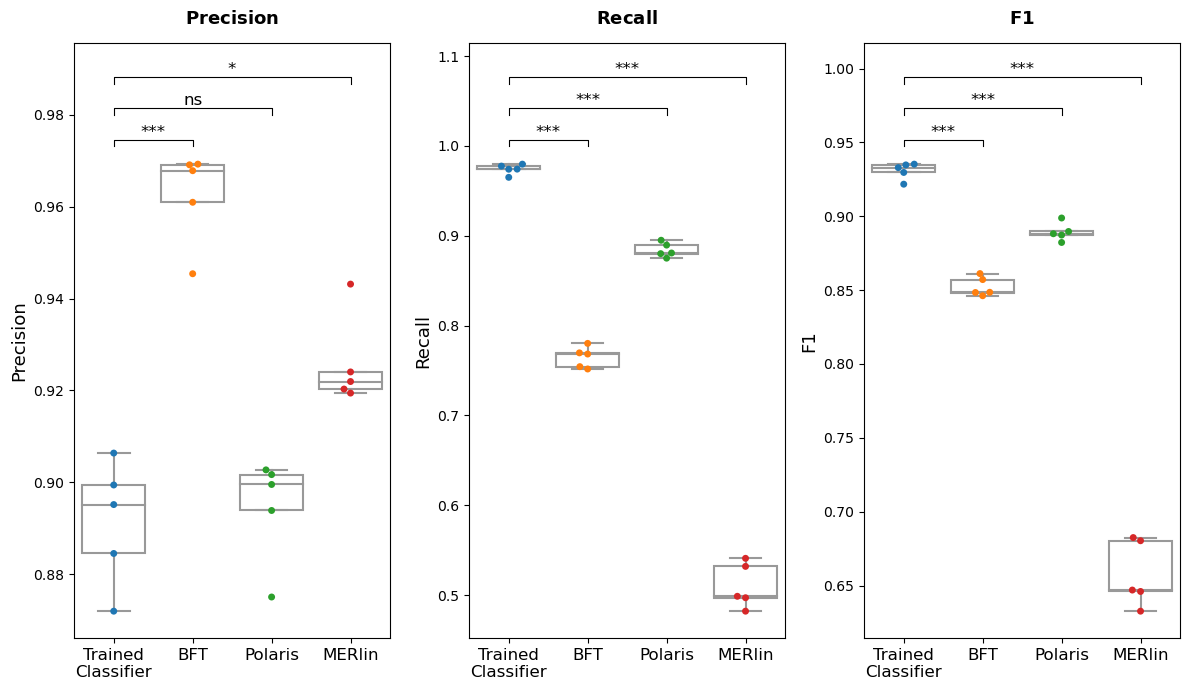

In [10]:
reference = 'model'
methods = ['model', 'bft', 'polaris', 'merlin']
labels  = {'model': 'Trained\nClassifier', 'bft': 'BFT',
           'polaris': 'Polaris', 'merlin': 'MERlin'}
titles  = {'precision': 'Precision', 'recall': 'Recall', 'f1': 'F1', 'auroc': 'AUROC'}

stats_results_df = compute_stats(results_df, methods,
                                 ['precision', 'recall', 'f1', 'auroc'], reference)
fig, axes = plot_benchmark(results_df, methods, ['precision', 'recall', 'f1'],
                           labels, titles, stats_results_df, figsize=(12, 7))
fig.savefig(os.path.join(output_dir, 'testset_results_cell_benchmark_crop_edge.svg'))

In [11]:
results_df.describe()

,fov,model_precision,model_recall,model_f1,model_auroc,bft_precision,bft_recall,bft_f1,bft_auroc,polaris_precision,polaris_recall,polaris_f1,polaris_auroc,merlin_precision,merlin_recall,merlin_f1,merlin_auroc
count,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000
mean,22.000000,0.891480,0.974069,0.930872,0.910261,0.962503,0.764869,0.852295,0.904391,0.894563,0.884105,0.889248,0.781491,0.925762,0.510275,0.657687,0.110477
std,1.581139,0.013489,0.005597,0.005571,0.011937,0.010154,0.011774,0.006506,0.012155,0.011439,0.008022,0.006036,0.013132,0.009870,0.025055,0.022395,0.007876
min,20.000000,0.871954,0.965010,0.921717,0.890190,0.945395,0.751736,0.846202,0.883535,0.875035,0.875064,0.882262,0.764615,0.919420,0.482249,0.632659,0.101440
25%,21.000000,0.884512,0.974016,0.929664,0.910441,0.960948,0.754333,0.848391,0.904891,0.893867,0.880081,0.887283,0.773468,0.920295,0.497193,0.646002,0.102844
50%,22.000000,0.895156,0.974140,0.932922,0.914288,0.967823,0.768374,0.848539,0.909292,0.899529,0.880795,0.888171,0.780802,0.921933,0.498800,0.646952,0.112887
75%,23.000000,0.899416,0.977504,0.934768,0.914654,0.969101,0.769684,0.857143,0.909642,0.901678,0.889610,0.889698,0.791757,0.924022,0.532080,0.680339,0.117008
max,24.000000,0.906364,0.979675,0.935288,0.921733,0.969247,0.780217,0.861203,0.914597,0.902706,0.894977,0.898825,0.796812,0.943137,0.541053,0.682484,0.118205


In [12]:
stats_results_df

,test,a,b,type,stat,p-value,stars
0,precision,bft,model,bft vs model,27.177459,1.089949e-05,***
1,precision,polaris,model,polaris vs model,0.621675,5.678337e-01,ns
2,precision,merlin,model,merlin vs model,4.136541,1.441700e-02,*
3,recall,bft,model,bft vs model,-60.569770,4.449782e-07,***
4,recall,polaris,model,polaris vs model,-31.547498,6.017111e-06,***
5,recall,merlin,model,merlin vs model,-43.815360,1.622330e-06,***
6,f1,bft,model,bft vs model,-20.013962,3.678114e-05,***
7,f1,polaris,model,polaris vs model,-13.841370,1.579325e-04,***
8,f1,merlin,model,merlin vs model,-26.053402,1.289555e-05,***
9,auroc,bft,model,bft vs model,-2.949889,4.197399e-02,*


ns  P > 0.05

//* P ≤ 0.05

** P ≤ 0.01

*** P ≤ 0.001

Using BFT as the 'reference' for pairwise comparison

In [13]:
compute_stats(results_df, methods,
                                 ['precision', 'recall', 'f1', 'auroc'], 'bft')

,test,a,b,type,stat,p-value,stars
0,precision,model,bft,model vs bft,-27.177459,1.089949e-05,***
1,precision,polaris,bft,polaris vs bft,-25.722901,1.356777e-05,***
2,precision,merlin,bft,merlin vs bft,-5.743801,4.553250e-03,**
3,recall,model,bft,model vs bft,60.569770,4.449782e-07,***
4,recall,polaris,bft,polaris vs bft,29.958350,7.393680e-06,***
5,recall,merlin,bft,merlin vs bft,-30.910474,6.526861e-06,***
6,f1,model,bft,model vs bft,20.013962,3.678114e-05,***
7,f1,polaris,bft,polaris vs bft,18.252575,5.299243e-05,***
8,f1,merlin,bft,merlin vs bft,-26.086030,1.283147e-05,***
9,auroc,model,bft,model vs bft,2.949889,4.197399e-02,*


# AUROC

<user_home>\AppData\Local\Temp\ipykernel_27276\2761639190.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Y_fov_subset['pred'] = RF.predict(fov_subset_transformed[features_to_use])
<user_home>\AppData\Local\Temp\ipykernel_27276\2761639190.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Y_fov_subset['pred_score'] = RF.predict_proba(fov_subset_transformed[features_to_use])[:, 1]
<user_home>\AppData\Local\Temp\ipykernel_27276\2761639190.py:30: SettingWithCopyWarning: 
A value is trying to be set on a

0.47620156290667703 0.7726792579463978
0.10146561443066517 0.7517356289919467
0.6073717948717948 0.8807947019867549
---
fov 20 90 797 2707 894
fov 20 379 245 3192 432
0.8872828353022932
---


<user_home>\AppData\Local\Temp\ipykernel_27276\2761639190.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Y_fov_subset['pred'] = RF.predict(fov_subset_transformed[features_to_use])
<user_home>\AppData\Local\Temp\ipykernel_27276\2761639190.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Y_fov_subset['pred_score'] = RF.predict_proba(fov_subset_transformed[features_to_use])[:, 1]
<user_home>\AppData\Local\Temp\ipykernel_27276\2761639190.py:30: SettingWithCopyWarning: 
A value is trying to be set on a

0.47620156290667703 0.7726792579463978
0.09942857142857142 0.7543328748280606
0.5378548895899053 0.8800807149034304
---
fov 21 87 788 2742 893
fov 21 341 293 3053 416
0.8896983826315022
---


<user_home>\AppData\Local\Temp\ipykernel_27276\2761639190.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Y_fov_subset['pred_score'] = RF.predict_proba(fov_subset_transformed[features_to_use])[:, 1]
<user_home>\AppData\Local\Temp\ipykernel_27276\2761639190.py:30: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  polaris_sub['pred'] = (polaris_sub['probability'] >= 0.95).astype(int) # define genes with probaility >= 0.95 to be true genes from Polaris
<user_home>\AppData\Local\Temp\ipykernel_27276\2761639190

0.47620156290667703 0.7726792579463978
0.16484607745779542 0.7696839850026781
0.5897771952817824 0.8896103896103896
---
fov 22 166 841 2874 860
fov 22 450 313 3151 391
0.8822623547529049
---
0.47620156290667703 0.7726792579463978
0.10679611650485436 0.7683741648106904
0.4908376963350785 0.8750636132315521
---
fov 23 99 828 3105 936
fov 23 375 389 3439 491
0.8881714876033058
---
0.47620156290667703 0.7726792579463978
0.11770623742454728 0.7802168021680217
0.5837651122625216 0.8949771689497716
---
fov 24 117 877 2879 811
fov 24 338 241 3136 368
0.8988248781885927
---


<user_home>\AppData\Local\Temp\ipykernel_27276\2761639190.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Y_fov_subset['pred'] = RF.predict(fov_subset_transformed[features_to_use])
<user_home>\AppData\Local\Temp\ipykernel_27276\2761639190.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Y_fov_subset['pred_score'] = RF.predict_proba(fov_subset_transformed[features_to_use])[:, 1]
<user_home>\AppData\Local\Temp\ipykernel_27276\2761639190.py:30: SettingWithCopyWarning: 
A value is trying to be set on a

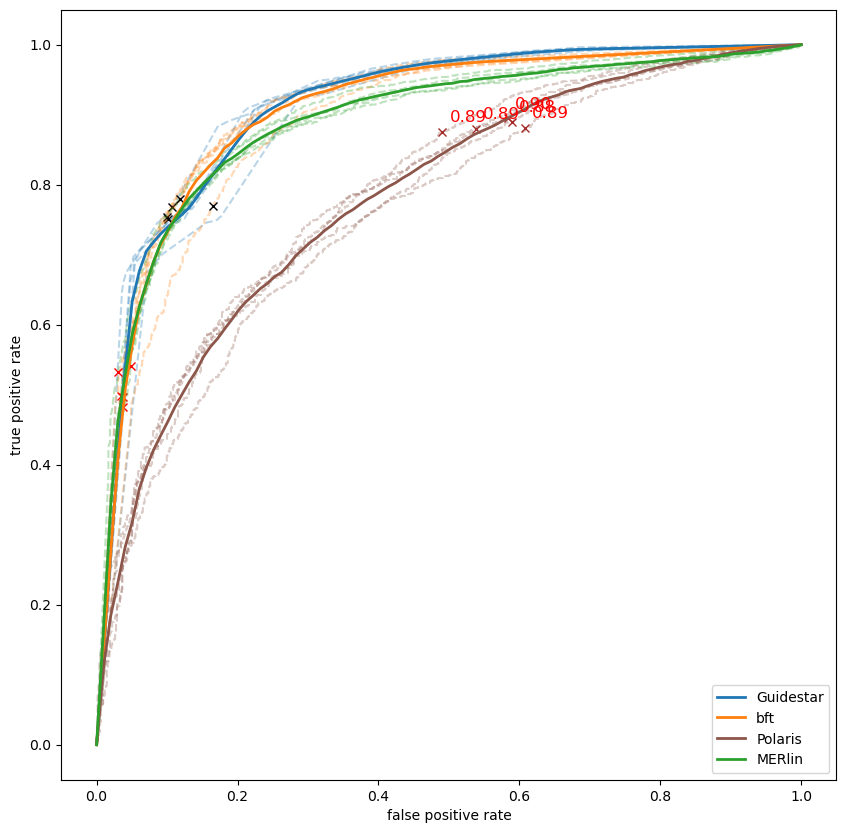

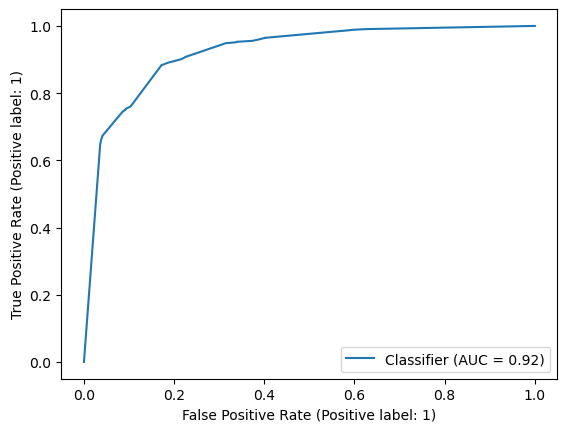

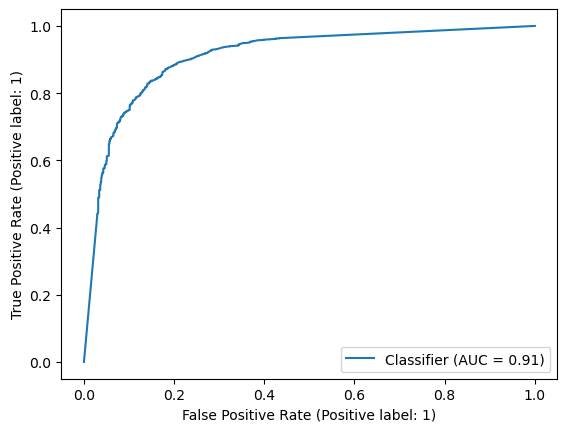

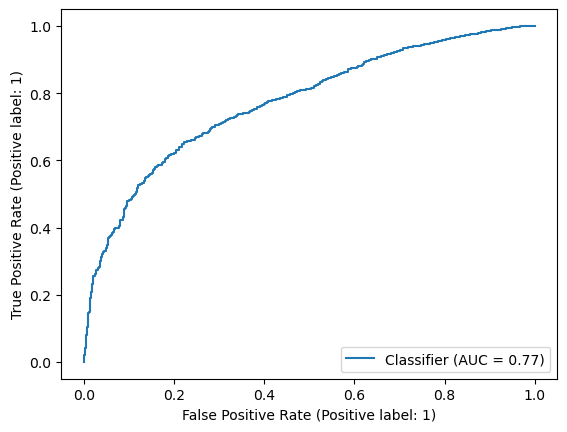

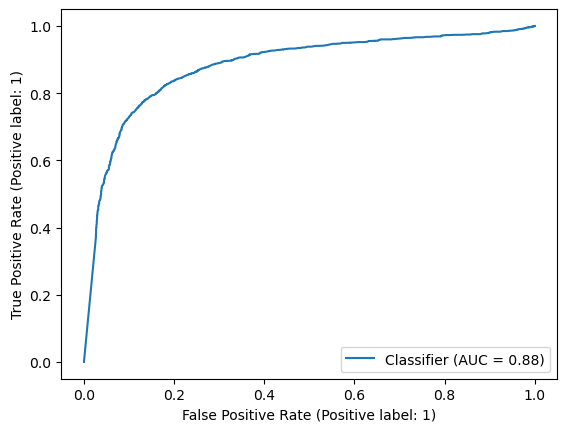

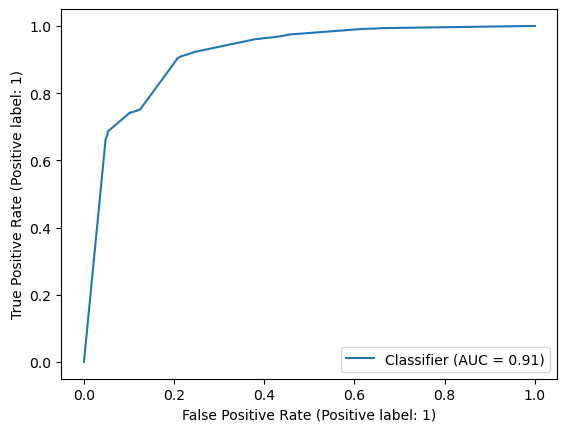

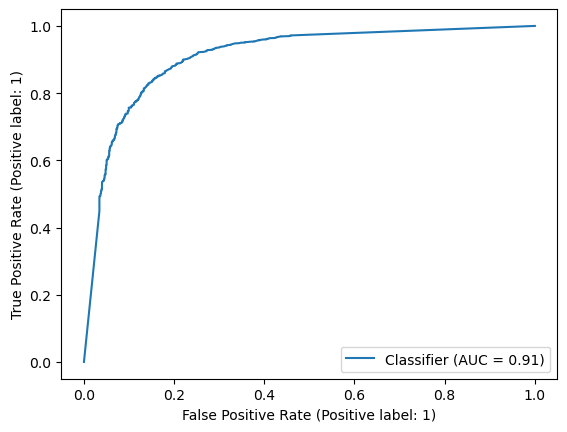

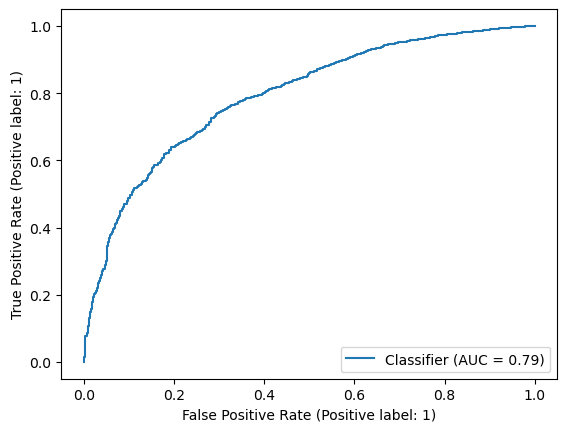

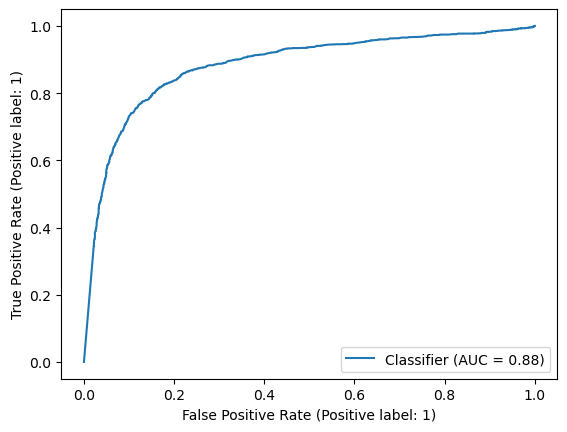

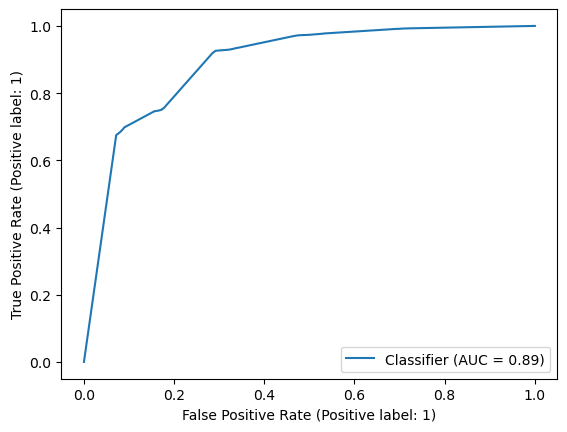

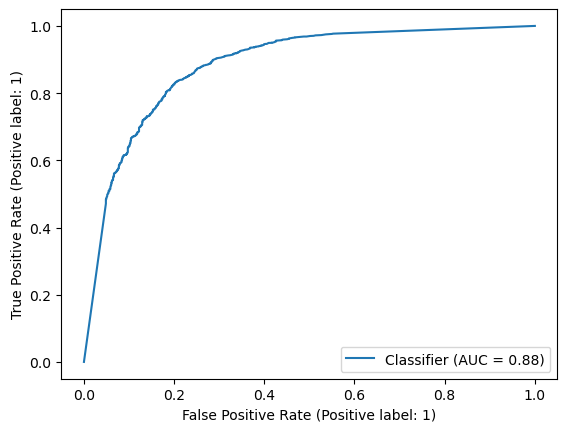

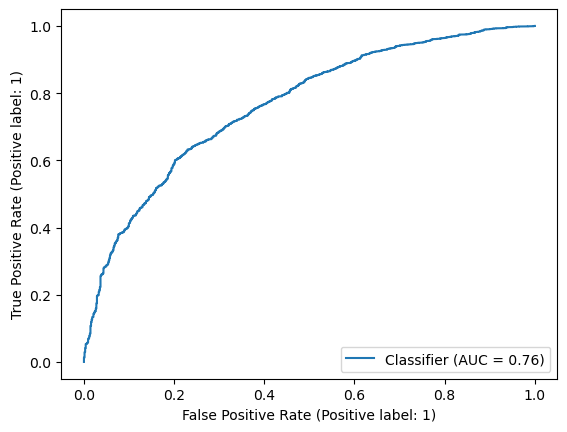

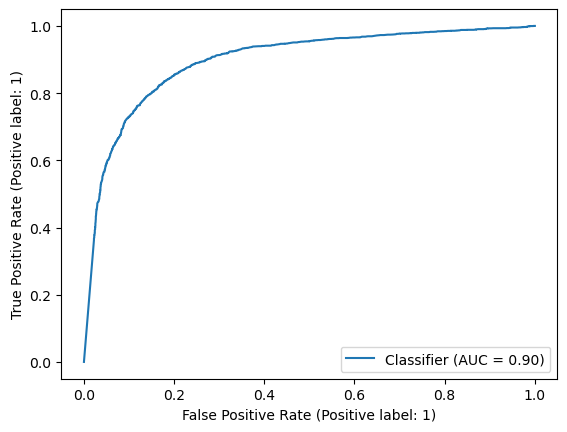

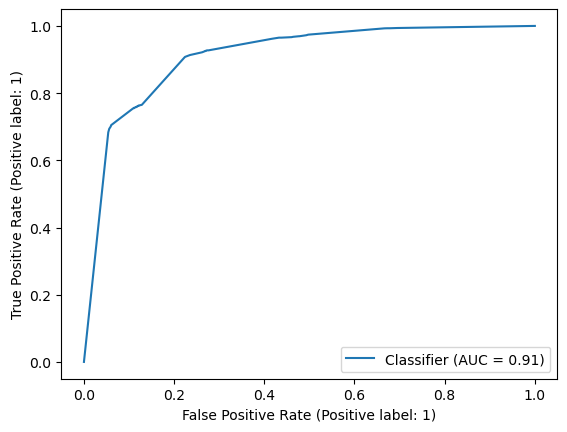

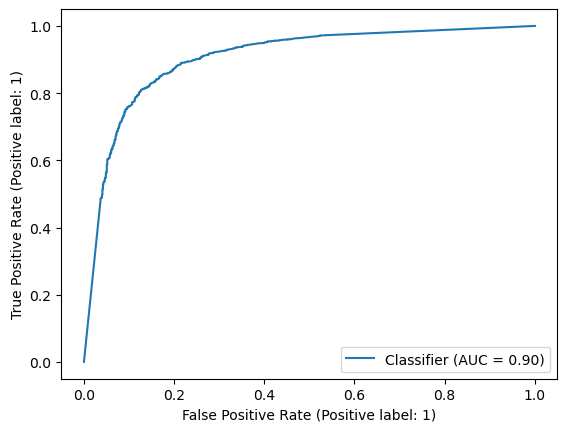

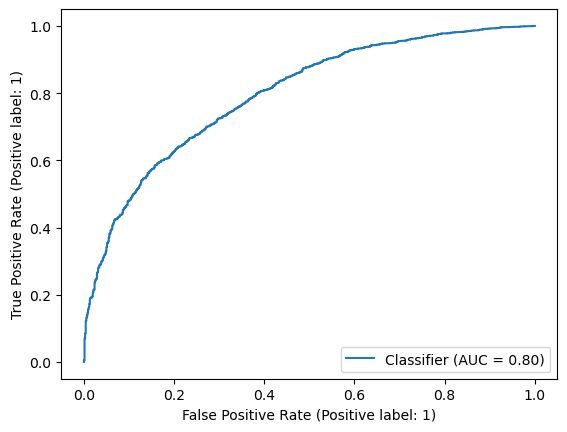

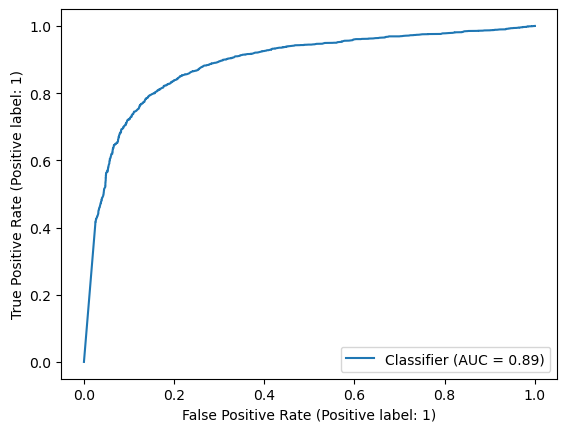

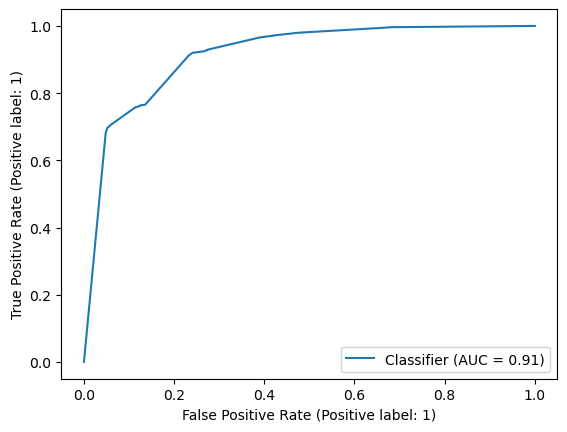

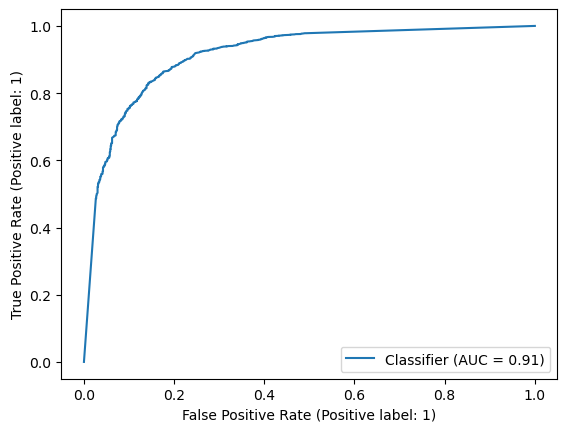

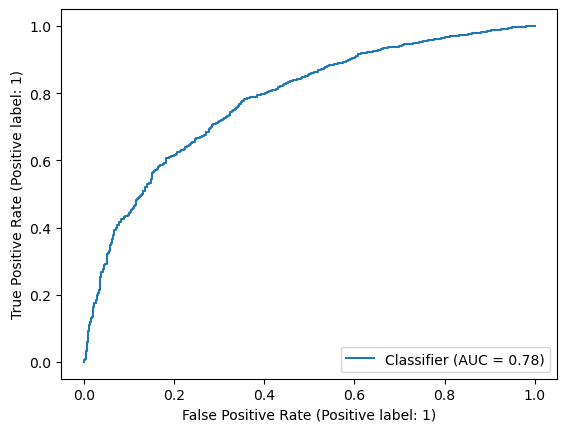

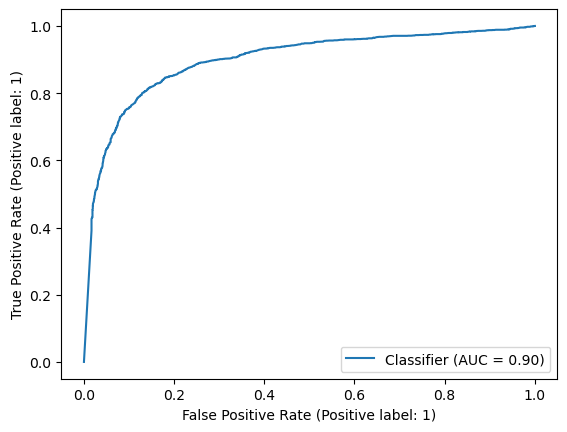

In [14]:
# ROC, AUC
### by fovs with misid, no error bars
tprs_model = []
fprs_model = []
aucs_model = []
tprs_bft = []
fprs_bft = []
aucs_bft = []
tprs_polaris = []
fprs_polaris = []
aucs_polaris = []
tprs_merlin = []
fprs_merlin = []
aucs_merlin = []
mean_fpr = np.linspace(0,1,100)

fig1,ax1=plt.subplots(1,1,figsize=(10,10))

for j,test_fov in enumerate(testing_fovs):
    fov_subset = X_test.loc[X_test['fov'] == test_fov]
    fov_subset_transformed = cm.transform(fov_subset[features_to_use])
    for col in fov_subset_transformed.columns:
        fov_subset_transformed[col] = fov_subset_transformed[col].fillna(fov_subset_transformed[col].max())
    Y_fov_subset = Y_test.loc[Y_test['fov'] == test_fov]
    Y_fov_subset['pred'] = RF.predict(fov_subset_transformed[features_to_use])
    Y_fov_subset['pred_score'] = RF.predict_proba(fov_subset_transformed[features_to_use])[:, 1]
    print(Y_fov_subset['pred_score'].min(),Y_fov_subset['pred_score'].max())

    polaris_sub = polaris_gs_data.loc[polaris_gs_data['fov'] == test_fov] 
    polaris_sub['pred'] = (polaris_sub['probability'] >= 0.95).astype(int) # define genes with probaility >= 0.95 to be true genes from Polaris
    
    merlin_sub = merlin_gs_data.loc[merlin_gs_data['fov'] == test_fov]
    merlin_sub['pred'] = merlin_sub['pass_threshold'].astype(int)

    roc_model=RocCurveDisplay.from_predictions(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                                               Y_fov_subset['pred_score'].loc[Y_fov_subset['gene'].isin(GS_gene_list)])
    roc_bft=RocCurveDisplay.from_predictions(Y_fov_subset['Label'].loc[Y_fov_subset['gene'].isin(GS_gene_list)],
                                             1-Y_fov_subset['bfs'].loc[Y_fov_subset['gene'].isin(GS_gene_list)])
    roc_polaris = RocCurveDisplay.from_predictions(polaris_sub['Label'].loc[polaris_sub['gene'].isin(GS_gene_list)], 
                                       polaris_sub['probability'].loc[polaris_sub['gene'].isin(GS_gene_list)])
    roc_merlin = RocCurveDisplay.from_predictions(merlin_sub['Label'].loc[merlin_sub['gene'].isin(GS_gene_list)], 
                                       1-merlin_sub['merlin_bfs'].loc[merlin_sub['gene'].isin(GS_gene_list)])
    
    aucs_model.append(roc_model.roc_auc)
    aucs_bft.append(roc_bft.roc_auc)
    aucs_polaris.append(roc_polaris.roc_auc)
    aucs_merlin.append(roc_merlin.roc_auc)

    interp_tpr_model = np.interp(mean_fpr,roc_model.fpr,roc_model.tpr)
    interp_tpr_model[0]=0
    # interp_fpr_model = np.interp(mean_fpr,roc_model.tpr,roc_model.fpr)
    # interp_fpr_model[0]=0
    tprs_model.append(interp_tpr_model)
    # fprs_model.append(interp_fpr_model)
    
    interp_tpr_bft = np.interp(mean_fpr,roc_bft.fpr,roc_bft.tpr)
    interp_tpr_bft[0]=0
    # interp_fpr_bft = np.interp(mean_fpr,roc_bft.tpr,roc_bft.fpr)
    # interp_fpr_bft[0]=0
    tprs_bft.append(interp_tpr_bft)
    # fprs_bft.append(interp_fpr_bft)

    interp_tpr_polaris = np.interp(mean_fpr,roc_polaris.fpr,roc_polaris.tpr)
    interp_tpr_polaris[0]=0
    # interp_fpr_polaris = np.interp(mean_fpr,roc_polaris.tpr,roc_polaris.fpr)
    # interp_fpr_polaris[0]=0
    tprs_polaris.append(interp_tpr_polaris)
    # fprs_polaris.append(interp_fpr_polaris)

    interp_tpr_merlin = np.interp(mean_fpr,roc_merlin.fpr,roc_merlin.tpr)
    interp_tpr_merlin[0]=0
    tprs_merlin.append(interp_tpr_merlin)

    ax1.plot(roc_model.fpr, roc_model.tpr, linestyle = 'dashed', alpha=0.3, color='tab:blue')
    ax1.plot(roc_bft.fpr, roc_bft.tpr, linestyle='dashed', alpha=0.3, color='tab:orange')
    ax1.plot(roc_polaris.fpr, roc_polaris.tpr, linestyle='dashed', alpha=0.3, color='tab:brown')
    ax1.plot(roc_merlin.fpr, roc_merlin.tpr, linestyle='dashed', alpha=0.3, color='tab:green')
    
    TP = len(Y_fov_subset.loc[(Y_fov_subset['Label']==1) & (Y_fov_subset['bft_result']==1)& (Y_fov_subset['gene'].isin(GS_gene_list))])
    FP = len(Y_fov_subset.loc[(Y_fov_subset['Label']==0) & (Y_fov_subset['bft_result']==1)& (Y_fov_subset['gene'].isin(GS_gene_list))])
    FN = len(Y_fov_subset.loc[(Y_fov_subset['Label']==1) & (Y_fov_subset['bft_result']==0)& (Y_fov_subset['gene'].isin(GS_gene_list))])
    TN = len(Y_fov_subset.loc[(Y_fov_subset['Label']==0) & (Y_fov_subset['bft_result']==0)& (Y_fov_subset['gene'].isin(GS_gene_list))])

    misid_fpr = FP / (FP+TN)
    misid_tpr = TP / (TP+FN)

    ax1.plot(misid_fpr, misid_tpr, 'x', color='black')
    print(misid_fpr, misid_tpr)

    ### polaris 0.95 plot
    TP_polaris = len(polaris_sub.loc[(polaris_sub['Label']==1) & (polaris_sub['pred']==1)& (polaris_sub['gene'].isin(GS_gene_list))])
    FP_polaris = len(polaris_sub.loc[(polaris_sub['Label']==0) & (polaris_sub['pred']==1)& (polaris_sub['gene'].isin(GS_gene_list))])
    FN_polaris = len(polaris_sub.loc[(polaris_sub['Label']==1) & (polaris_sub['pred']==0)& (polaris_sub['gene'].isin(GS_gene_list))])
    TN_polaris = len(polaris_sub.loc[(polaris_sub['Label']==0) & (polaris_sub['pred']==0)& (polaris_sub['gene'].isin(GS_gene_list))])
    misid_polaris_fpr = FP_polaris / (FP_polaris+TN_polaris)
    misid_polaris_tpr = TP_polaris / (TP_polaris+FN_polaris)
    ax1.plot(misid_polaris_fpr, misid_polaris_tpr, 'x', color='brown')
    polaris_95_score = f1_score(polaris_sub['Label'].loc[polaris_sub['gene'].isin(GS_gene_list)], polaris_sub['pred'].loc[polaris_sub['gene'].isin(GS_gene_list)])
    ax1.text(misid_polaris_fpr + 0.01, misid_polaris_tpr + 0.01, f'{polaris_95_score:.2f}',
         color='red', fontsize=12, ha='left', va='bottom')
    
    print(misid_polaris_fpr, misid_polaris_tpr)
    print('---')
    print('fov', test_fov, FP, TN, TP, FN)
    print('fov', test_fov, FP_polaris, TN_polaris, TP_polaris, FN_polaris)
    print(polaris_95_score)
    print('---')

    TP_merlin = len(merlin_sub.loc[(merlin_sub['Label']==1) & (merlin_sub['pred']==1) &
                                   (merlin_sub['gene'].isin(GS_gene_list))])
    FP_merlin = len(merlin_sub.loc[(merlin_sub['Label']==0) & (merlin_sub['pred']==1) &
                                   (merlin_sub['gene'].isin(GS_gene_list))])
    FN_merlin = len(merlin_sub.loc[(merlin_sub['Label']==1) & (merlin_sub['pred']==0) &
                                   (merlin_sub['gene'].isin(GS_gene_list))])
    TN_merlin = len(merlin_sub.loc[(merlin_sub['Label']==0) & (merlin_sub['pred']==0) &
                                   (merlin_sub['gene'].isin(GS_gene_list))])
    misid_merlin_fpr = FP_merlin / (FP_merlin+TN_merlin)
    misid_merlin_tpr = TP_merlin/ (TP_merlin+FN_merlin)
    ax1.plot(misid_merlin_fpr, misid_merlin_tpr, 'x', color='red')
    
mean_tpr_model = np.mean(tprs_model,axis=0)
mean_tpr_model[-1]=1
mean_tpr_bft = np.mean(tprs_bft,axis=0)
mean_tpr_bft[-1]=1
mean_tpr_polaris = np.mean(tprs_polaris,axis=0)
mean_tpr_polaris[-1]=1
mean_tpr_merlin = np.mean(tprs_merlin, axis=0)
mean_tpr_merlin[-1]=1
ax1.plot(mean_fpr,mean_tpr_model,color='tab:blue', linewidth=2, label='Guidestar')
ax1.plot(mean_fpr,mean_tpr_bft,color='tab:orange', linewidth=2, label='bft')
ax1.plot(mean_fpr,mean_tpr_polaris,color='tab:brown', linewidth=2, label='Polaris')
ax1.plot(mean_fpr,mean_tpr_merlin,color='tab:green', linewidth=2, label='MERlin')
ax1.legend(loc='lower right')
ax1.set_xlabel('false positive rate')
ax1.set_ylabel('true positive rate')
fig1.savefig(os.path.join(output_dir, 'ROC_withmisid_crop_edge_polaris.svg'))

In [15]:
from sklearn.metrics import auc

auc_mean_model   = auc(mean_fpr, mean_tpr_model)
auc_mean_bft     = auc(mean_fpr, mean_tpr_bft)
auc_mean_polaris = auc(mean_fpr, mean_tpr_polaris)
auc_mean_merlin   = auc(mean_fpr, mean_tpr_merlin)

print(f'AUC mean for Trained Classifier: {auc_mean_model:.3f}')
print(f'AUC mean for BFT: {auc_mean_bft:.3f}')
print(f'AUC mean for Polaris: {auc_mean_polaris:.3f}')
print(f'AUC mean for MERlin: {auc_mean_merlin:.3f}')

AUC mean for Trained Classifier: 0.910
AUC mean for BFT: 0.904
AUC mean for Polaris: 0.781
AUC mean for MERlin: 0.889


# Predicted MERFISH result FPKM, Counts

In [16]:
# merfish by fov
model_fpkm_result = []
model_counts_result = []
model_misid_result = []

bft_fpkm_result = []
bft_counts_result = []
bft_misid_result = []

all_model_callouts = []
all_bft_callouts = []

merfish_data['bft_result'] = 0
merfish_data.loc[merfish_data['bfs'] <= bft, 'bft_result'] = 1
for merfish_fov in range(nfovs):
    merfish_subset = merfish_data[features_to_use + ['bfs', 'bft_result', 'gene']].loc[merfish_data['fov'] == merfish_fov]
    merfish_subset_transformed = cm.transform(merfish_subset[features_to_use])
    for col in merfish_subset_transformed.columns:
        merfish_subset_transformed[col] = merfish_subset_transformed[col].fillna(merfish_subset_transformed[col].max())
    merfish_subset_transformed['pred'] = RF.predict(merfish_subset_transformed[features_to_use])
    model_callouts = list(merfish_subset['gene'].loc[merfish_subset_transformed['pred']==1])
    model_counts_arr, _, fpkm_list = plot_fpkm_corr(df_fpkm, model_callouts)
    model_fpkm_val, _ = calcLogCorrelation(np.array(model_counts_arr), np.array(fpkm_list))
    model_mis_id_rate = calc_misid(model_counts_arr, model_callouts)
    
    bft_callouts = list(merfish_subset['gene'].loc[merfish_subset['bft_result']==1])
    bft_counts_arr, _, fpkm_list = plot_fpkm_corr(df_fpkm, bft_callouts)
    bft_fpkm_val, _ = calcLogCorrelation(np.array(bft_counts_arr), np.array(fpkm_list))
    bft_mis_id_rate = calc_misid(bft_counts_arr, bft_callouts)
    
    model_fpkm_result.append(model_fpkm_val)
    model_counts_result.append(np.sum(model_counts_arr))
    model_misid_result.append(model_mis_id_rate)
    
    bft_fpkm_result.append(bft_fpkm_val)
    bft_counts_result.append(np.sum(bft_counts_arr))
    bft_misid_result.append(bft_mis_id_rate)

    all_model_callouts.extend(model_callouts)
    all_bft_callouts.extend(bft_callouts)

In [17]:
# load process data 
polaris_fpkm_result = []
polaris_counts_result = []
polaris_fov = []

all_polaris_callouts = []

folder = Path(os.path.join(main_dir, 'Data/benchmarking/polaris/cell/Relaxed Bernoulli_thresh0.85_GS_chrco_img_regi_final/polaris_LM39cell_result_edgecrop/'))
for file in folder.glob('*Polaris_prediction.csv'):
    fov = int(file.name.split('_')[0])
    polaris_fov.append(fov)
    df_polaris_sub = pd.read_csv(file)

    ### keep only probability >= 0.95
    df_polaris_sub = df_polaris_sub[df_polaris_sub['probability'] >= 0.95]
    polaris_counts_arr, _, fpkm_list = plot_fpkm_corr(df_fpkm, df_polaris_sub['predicted_name'].tolist())
    polaris_fpkm_val, _ = calcLogCorrelation(np.array(polaris_counts_arr), np.array(fpkm_list))
    polaris_fpkm_result.append(polaris_fpkm_val)
    polaris_counts_result.append(np.sum(polaris_counts_arr))
    all_polaris_callouts.extend(df_polaris_sub['predicted_name'].tolist())
### format polaris output
polaris_df_result = pd.DataFrame({'fov':polaris_fov, 'polaris_fpkm': polaris_fpkm_result,
                                  'polaris_count': polaris_counts_result})

In [18]:
# this is matching starfish global normalization (for scale factor computation) to 99.9 percentile & 57 median in GS 
starfish_fpkm_result_v2 = []
starfish_counts_result_v2 = []
df_starfish_v2 = pd.read_csv(os.path.join(main_dir, 'Data/benchmarking/starfish/cell/starfish_result/lm39_aml_starfish_run10_multifov.csv'))
for sub_fov in range(25):
    df_starfish_sub_v2 = df_starfish_v2[df_starfish_v2['fov'] == f'fov_{str(sub_fov).zfill(3)}']
    starfish_counts_arr_v2, _, fpkm_list_v2 = plot_fpkm_corr(df_fpkm, df_starfish_sub_v2['target'].tolist())
    starfish_fpkm_val_v2, _ = calcLogCorrelation(np.array(starfish_counts_arr_v2), np.array(fpkm_list_v2))
    starfish_fpkm_result_v2.append(starfish_fpkm_val_v2)
    starfish_counts_result_v2.append(np.sum(starfish_counts_arr_v2))

In [19]:
### process MERlin
merlin_fpkm_result = []
merlin_counts_result= []
merlin_fov = []

all_merlin_callouts = []

for fov in range(25):
    merlin_fov.append(fov)
    file = os.path.join(merlin_path,f'Adaptivefilter_{fov}.csv')
    df_merlin_sub = pd.read_csv(file)
    df_merlin_sub['gene_name'] = df_merlin_sub['barcode_id'].map(df_fpkm['genes'].to_dict())
    df_merlin_sub = df_merlin_sub[df_merlin_sub['passes_threshold']==True] # only select data that pass Adaptive Filtering in MERlin
    merlin_counts_arr, _, fpkm_list = plot_fpkm_corr(df_fpkm, df_merlin_sub['gene_name'].tolist())
    merlin_fpkm_val, _ = calcLogCorrelation(np.array(merlin_counts_arr), np.array(fpkm_list))
    merlin_fpkm_result.append(merlin_fpkm_val)
    merlin_counts_result.append(np.sum(merlin_counts_arr))
    all_merlin_callouts.extend(df_merlin_sub['gene_name'].tolist())

import h5py
import pandas as pd

with h5py.File("../Benchmarking/LM39CELLMERlinAdaptiveFilter_result.h5", "r") as f:
    data = {col: f[col][()] for col in f.keys()}

gs_merlin = pd.DataFrame(data)
gs_merlin["genes"] = gs_merlin["genes"].astype("S").str.decode("utf-8")
gs_merlin['fovs'] = gs_merlin['fovs'].astype(int)

gs_merlin_fpkm = []
gs_merlin_counts= []
gs_merlin_fov = []

for fov in range(25):
    gs_merlin_fov.append(fov)
    gs_merlin_sub = gs_merlin[(gs_merlin['fovs'] == fov) & (gs_merlin['pass_threshold'])].copy()
    gs_merlin_counts_array, _, fpkm_list = plot_fpkm_corr(df_fpkm, gs_merlin_sub['genes'].tolist())
    gs_merlin_fpkm_val, _ = calcLogCorrelation(np.array(gs_merlin_counts_array), np.array(fpkm_list))
    gs_merlin_fpkm.append(gs_merlin_fpkm_val)
    gs_merlin_counts.append(np.sum(gs_merlin_counts_array))

# same (blankHis/geneHis), areaBins match GS to 4 bins
with h5py.File("../Benchmarking/LM39CELLMERlinAdaptiveFilter_result_matchGS_sizebins.h5", "r") as f:
    data = {col: f[col][()] for col in f.keys()}

gs_merlin3 = pd.DataFrame(data)
gs_merlin3["genes"] = gs_merlin3["genes"].astype("S").str.decode("utf-8")
gs_merlin3['fovs'] = gs_merlin3['fovs'].astype(int)

gs_merlin_fpkm3 = []
gs_merlin_counts3= []
gs_merlin_fov3 = []

for fov in range(25):
    gs_merlin_fov3.append(fov)
    gs_merlin_sub3 = gs_merlin3[(gs_merlin3['fovs'] == fov) & (gs_merlin3['pass_threshold'])].copy()
    gs_merlin_counts_array3, _, fpkm_list = plot_fpkm_corr(df_fpkm, gs_merlin_sub3['genes'].tolist())
    gs_merlin_fpkm_val, _ = calcLogCorrelation(np.array(gs_merlin_counts_array3), np.array(fpkm_list))
    gs_merlin_fpkm3.append(gs_merlin_fpkm_val)
    gs_merlin_counts3.append(np.sum(gs_merlin_counts_array3))

# match everything
import h5py
import pandas as pd
with h5py.File("../Benchmarking/LM39CELLMERlinAdaptiveFilter_result_matchGS_everything.h5", "r") as f:
    data = {col: f[col][()] for col in f.keys()}

gs_merlin4 = pd.DataFrame(data)
gs_merlin4["genes"] = gs_merlin4["genes"].astype("S").str.decode("utf-8")
gs_merlin4['fovs'] = gs_merlin4['fovs'].astype(int)

gs_merlin_fpkm4 = []
gs_merlin_counts4= []
gs_merlin_fov4 = []

for fov in range(25):
    gs_merlin_fov4.append(fov)
    gs_merlin_sub4 = gs_merlin4[(gs_merlin4['fovs'] == fov) & (gs_merlin4['pass_threshold'])].copy()
    gs_merlin_counts_array4, _, fpkm_list = plot_fpkm_corr(df_fpkm, gs_merlin_sub4['genes'].tolist())
    gs_merlin_fpkm_val, _ = calcLogCorrelation(np.array(gs_merlin_counts_array4), np.array(fpkm_list))
    gs_merlin_fpkm4.append(gs_merlin_fpkm_val)
    gs_merlin_counts4.append(np.sum(gs_merlin_counts_array4))

In [20]:
merfish_results_df = pd.DataFrame({'fov':[i for i in range(25)], 
                                   'model_fpkm': model_fpkm_result, 'model_counts':model_counts_result, 'model_misid': model_misid_result,
                                   'bft_fpkm': bft_fpkm_result, 'bft_counts': bft_counts_result, 'bft_misid': bft_misid_result,
                                   'starfish_fpkm': starfish_fpkm_result_v2, 'starfish_counts': starfish_counts_result_v2,
                                   'polaris_fpkm': polaris_df_result['polaris_fpkm'].tolist(), 'polaris_counts': polaris_df_result['polaris_count'].tolist(),
                                   'merlin_fpkm': merlin_fpkm_result, 'merlin_counts': merlin_counts_result
                                   })
merfish_results_df.to_csv(os.path.join(output_dir, 'full_benchmarking_merfish_results_cell_crop_edge.csv'))
merfish_results_df_long = pd.melt(merfish_results_df,id_vars=['fov'])

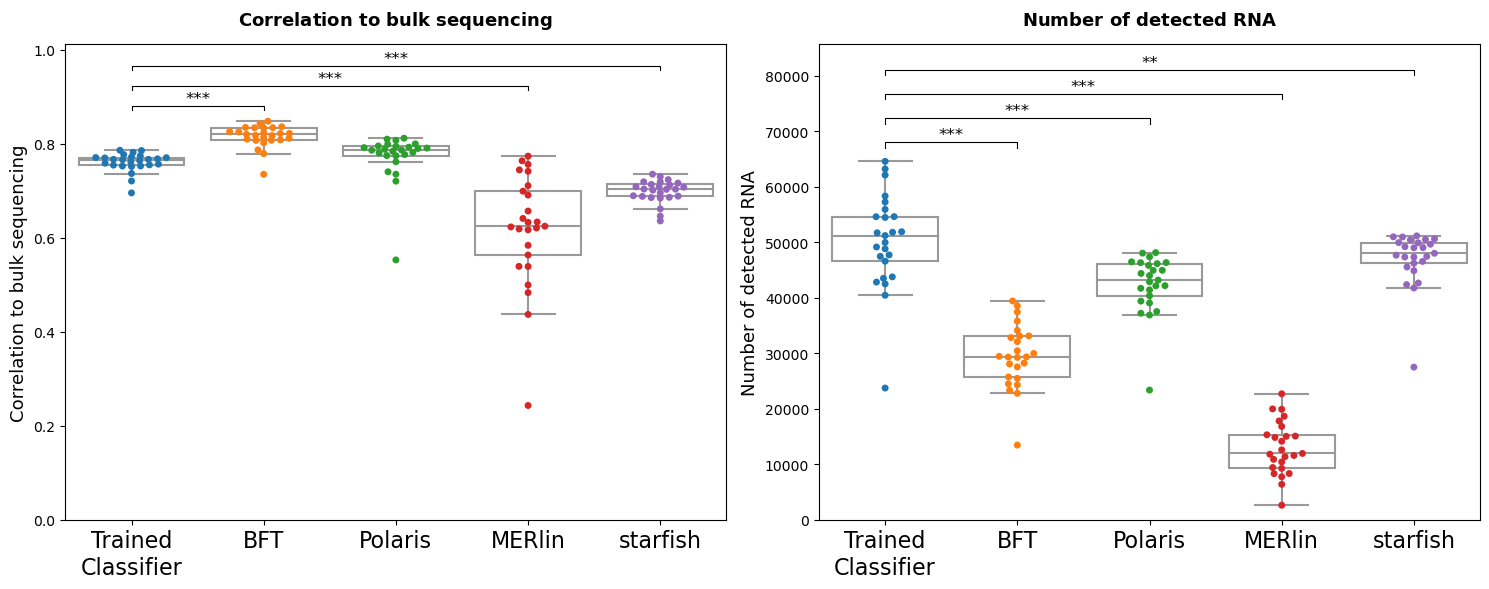

In [21]:
methods_all = ['model', 'bft', 'polaris', 'merlin', 'starfish']
labels_all  = {**labels, 'starfish': 'starfish'}
colors      = {'model': '#1f77b4', 'bft': '#ff7f0e', 'polaris': '#2ca02c',
               'merlin': '#d62728', 'starfish': '#9467bd'}
titles_cnt  = {'fpkm': 'Correlation to bulk sequencing', 'counts': 'Number of detected RNA'}

count_results_df = compute_stats(merfish_results_df, methods_all,
                                 ['fpkm', 'counts'], reference)
fig, axes = plot_benchmark(merfish_results_df, methods_all, ['fpkm', 'counts'],
                           labels_all, titles_cnt, count_results_df,
                           colors=colors, show_ns=False, ymin_zero=True,
                           figsize=(15, 6), tick_fontsize=16)
fig.savefig(os.path.join(output_dir,
            'benchmark_merfish_results_cell_withwhole_model_stats_p_crop_edge.svg'))

In [22]:
merfish_results_df.describe()

,fov,model_fpkm,model_counts,model_misid,bft_fpkm,bft_counts,bft_misid,starfish_fpkm,starfish_counts,polaris_fpkm,polaris_counts,merlin_fpkm,merlin_counts
count,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.00000,25.000000,25.000000
mean,12.000000,0.760398,50333.160000,0.300864,0.815657,29506.040000,0.052471,0.698374,47070.800000,0.772816,42413.56000,0.617234,12907.240000
std,7.359801,0.019855,8559.775312,0.034944,0.023304,5703.769371,0.011059,0.023958,4918.144442,0.050998,5214.92337,0.119181,4773.052712
min,0.000000,0.695227,23729.000000,0.250010,0.734796,13446.000000,0.038148,0.635585,27499.000000,0.552634,23364.00000,0.242948,2610.000000
25%,6.000000,0.754309,46598.000000,0.276391,0.807971,25725.000000,0.047523,0.687795,46229.000000,0.774658,40365.00000,0.563161,9399.000000
50%,12.000000,0.765823,51214.000000,0.297396,0.819852,29351.000000,0.051383,0.703099,48020.000000,0.786425,43188.00000,0.624356,11942.000000
75%,18.000000,0.770434,54624.000000,0.311235,0.833460,33099.000000,0.056298,0.713228,49947.000000,0.794213,46149.00000,0.698835,15301.000000
max,24.000000,0.785897,64590.000000,0.424137,0.847735,39426.000000,0.096391,0.735027,51161.000000,0.811584,48138.00000,0.773399,22691.000000


,test,a,b,type,stat,p-value,stars
0,fpkm,bft,model,bft vs model,35.906187,2.256086e-22,***
1,fpkm,polaris,model,polaris vs model,1.152889,2.603097e-01,ns
2,fpkm,merlin,model,merlin vs model,-6.186717,2.156714e-06,***
3,fpkm,starfish,model,starfish vs model,-20.428351,1.106673e-16,***
4,counts,bft,model,bft vs model,-34.127242,7.467971e-22,***
5,counts,polaris,model,polaris vs model,-4.868518,5.802562e-05,***
6,counts,merlin,model,merlin vs model,-34.616539,5.341520e-22,***
7,counts,starfish,model,starfish vs model,-3.478518,1.942844e-03,**


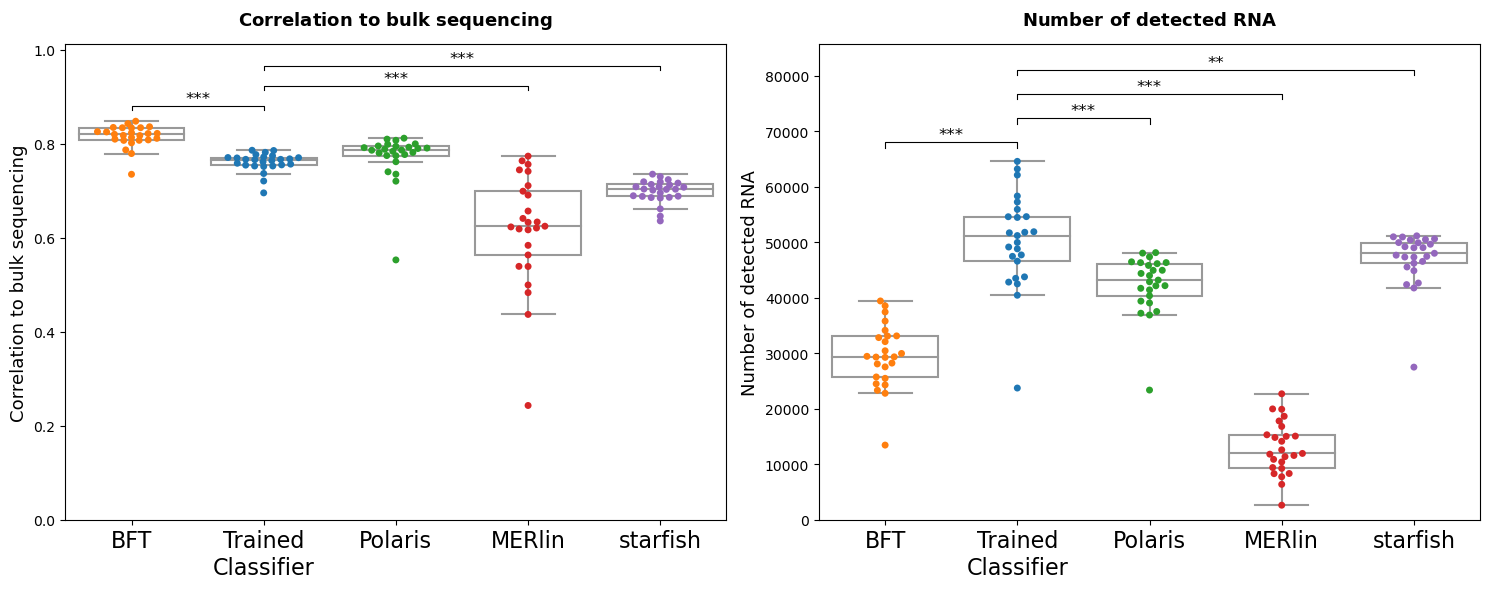

In [32]:
methods_all = ['bft', 'model', 'polaris', 'merlin', 'starfish']   # BFT at x=0, classifier at x=1

reference = 'model'
count_results_df = compute_stats(merfish_results_df, methods_all,
                                 ['fpkm', 'counts'], reference)
fig, axes = plot_benchmark(merfish_results_df, methods_all, ['fpkm', 'counts'],
                           labels_all, titles_cnt, count_results_df,
                           colors=colors, show_ns=False, ymin_zero=True,
                           figsize=(15, 6), tick_fontsize=16)

fig.savefig(os.path.join(output_dir, 'benchmark_merfish_results_cell_withwhole_model_stats_ref_BFT_p_crop.svg'))
count_results_df

In [24]:
# compute column sum for merfish_results_df
merfish_results_df.sum()

fov                3.000000e+02
model_fpkm         1.900996e+01
model_counts       1.258329e+06
model_misid        7.521604e+00
bft_fpkm           2.039143e+01
bft_counts         7.376510e+05
bft_misid          1.311771e+00
starfish_fpkm      1.745935e+01
starfish_counts    1.176770e+06
polaris_fpkm       1.932041e+01
polaris_counts     1.060339e+06
merlin_fpkm        1.543084e+01
merlin_counts      3.226810e+05
dtype: float64

In [30]:
merfish_results_df.sum().iloc[2]/merfish_results_df.sum()

fov                  4194.430000
model_fpkm          66193.151216
model_counts            1.000000
model_misid        167295.306916
bft_fpkm            61708.704405
bft_counts              1.705860
bft_misid          959259.492827
starfish_fpkm       72071.932011
starfish_counts         1.069308
polaris_fpkm        65129.528056
polaris_counts          1.186723
merlin_fpkm         81546.348826
merlin_counts           3.899607
dtype: float64

## Compute the FPKM correlation for each method over ALL FOVs 
each point is 1 gene of interest

In [26]:
from typing import Mapping, Optional, Tuple
from matplotlib.ticker import LogLocator, NullFormatter

def plotFPKMCorrelation(datasets: Mapping[str, pd.DataFrame],
                        fpkm_column: str = "FPKM",
                        count_column: str = "spot_count",
                        colours: Optional[Mapping[str, str]] = None,
                        labels: Optional[Mapping[str, str]] = None,
                        title: str = "AML-12 cell line sample",
                        subtitle: str = "Correlation of spot counts with RNAseq FPKM value",
                        xlabel: str = "FPKM value",
                        ylabel: str = "RNA spot counts",
                        xlim: Tuple[float, float] = (1e-3, 3e2),
                        ylim: Tuple[float, float] = (7e1, 4e5),
                        point_size: float = 16,
                        alpha: float = 0.85,
                        figsize: Tuple[float, float] = (5.2, 4.6),
                        ax: Optional[plt.Axes] = None,
                        ):
    """
    datasets: {"Guidestar": merged_df, "BFT": merged_df} where each merged_df
    has an FPKM column and a spot-count column.
 
    returns (fig, ax, {label: (correlation, p_value)})
    """
    colours = dict(DEFAULT_COLOURS) if colours is None else dict(colours)
    labels = {} if labels is None else dict(labels)
 
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize, dpi=150)
    else:
        fig = ax.figure
 
    correlations = {}
 
    for i, (key, df) in enumerate(datasets.items()):
        label = labels.get(key, key)
        fpkm_values = np.asarray(df[fpkm_column], dtype=float)
        spot_counts = np.asarray(df[count_column], dtype=float)
        colour = colours.get(key, colours.get(label, f"C{i}"))
 
        ax.scatter(fpkm_values, spot_counts,
                   s=point_size, color=colour, alpha=alpha,
                   linewidths=0, label=label, zorder=3)
 
        correlation, p_value = calcLogCorrelation(fpkm_values, spot_counts)
        correlations[key] = (correlation, p_value)
 
        ax.text(0.035, 0.965 - 0.085 * i, f"{label} = {correlation:.3f}",
                transform=ax.transAxes, ha="left", va="top",
                color=colour, fontsize=10, fontweight="bold", zorder=4)
 
    # --- log-log axes ---
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.xaxis.set_major_locator(LogLocator(base=10.0))
    ax.yaxis.set_major_locator(LogLocator(base=10.0))
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_minor_locator(LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1))
        axis.set_minor_formatter(NullFormatter())
 
    # --- styling: grey panel, white gridlines, no spines ---
    ax.set_facecolor("#EAEAF2")
    ax.grid(True, which="major", color="white", linewidth=1.0)
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(which="major", length=3, width=0.8, colors="#333333", labelsize=9)
    ax.tick_params(which="minor", length=0)
 
    ax.set_xlabel(xlabel, fontsize=10)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_title(title, fontsize=12, fontweight="bold", pad=24)
    ax.text(0.5, 1.025, subtitle, transform=ax.transAxes,
            ha="center", va="bottom", fontsize=9)
 
    fig.tight_layout()
    return fig, ax, correlations

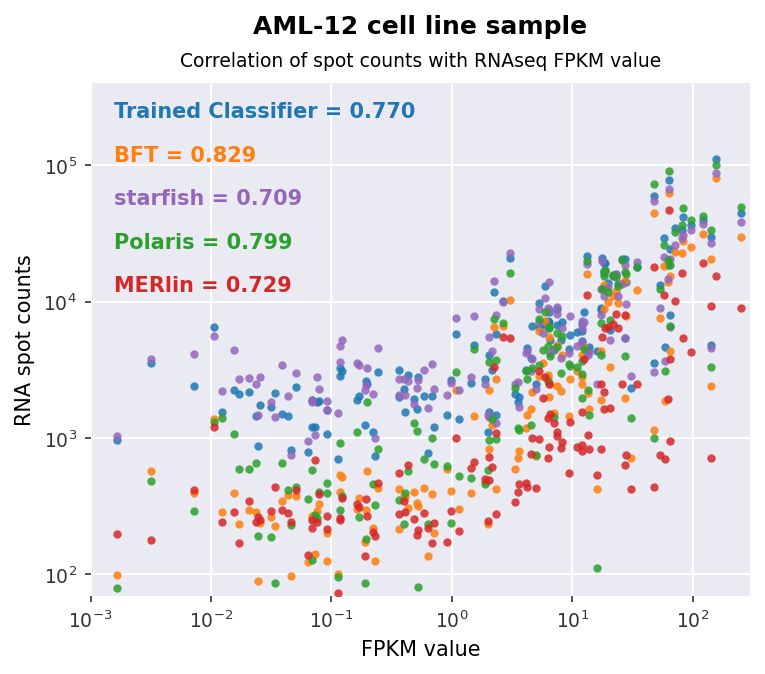

In [27]:
pooled = df_fpkm[["genes", "FPKM"]].copy().set_index("genes")   # adjust column names
pooled["model_counts"] = pd.Series(Counter(all_model_callouts)).reindex(pooled.index).fillna(0)
pooled["bft_counts"] = pd.Series(Counter(all_bft_callouts)).reindex(pooled.index).fillna(0)
all_starfish_callouts = df_starfish_v2['target'].tolist()
pooled["starfish_counts"] = pd.Series(Counter(all_starfish_callouts)).reindex(pooled.index).fillna(0)
pooled["polaris_counts"] = pd.Series(Counter(all_polaris_callouts)).reindex(pooled.index).fillna(0)
pooled['merlin_counts'] = pd.Series(Counter(all_merlin_callouts)).reindex(pooled.index).fillna(0)

datasets = {
    "model": pooled.rename(columns={"model_counts": "spot_count"}),
    "bft": pooled.rename(columns={"bft_counts": "spot_count"}),
    "starfish": pooled.rename(columns={"starfish_counts": "spot_count"}),
    'polaris': pooled.rename(columns={"polaris_counts": "spot_count"}),
    'merlin': pooled.rename(columns={"merlin_counts": "spot_count"})
}
 
labels = {"model": "Trained Classifier", "bft": "BFT", "starfish": "starfish",
          "polaris": "Polaris", "merlin": "MERlin"}

fig, ax, correlations = plotFPKMCorrelation(datasets, colours=colors, labels=labels)
fig.savefig(os.path.join(output_dir, 'FPKM_correlation_all_methods_cell_p_crop.svg'))

In [28]:
pooled.sum()

FPKM               2.367351e+03
model_counts       1.258329e+06
bft_counts         7.376510e+05
starfish_counts    1.176770e+06
polaris_counts     1.060339e+06
merlin_counts      3.226810e+05
dtype: float64

In [29]:
pooled.sum().iloc[1]/pooled.sum()

FPKM               531.534707
model_counts         1.000000
bft_counts           1.705860
starfish_counts      1.069308
polaris_counts       1.186723
merlin_counts        3.899607
dtype: float64